# 第 9 课 · BLP 需求、企业定价与兼并反事实

现在有四件商品。A 和 B 原来分别属于两家企业，C 和 D 一直由第三家企业经营。若 A 和 B 的所有者合并，市场需求有没有立即变化？企业重新定价之后，消费者和产品销售又会怎样变化？

**课堂建议 3 学时。** [第 8 课](08-blp-demand.ipynb)用产品—市场数据估计随机系数需求。本课沿用同一种需求形式，用一个边际成本和需求参数已知的模拟市场练习供给反演，便于核对每一个结果。产品的需求系数、市场规模及边际成本由例子给定。模型采用静态多产品 Bertrand 定价，企业同时选价，边际成本为常数。

完成后，学生应能推导需求导数、用所有权矩阵反演边际成本、计算价格固定和允许企业重新定价两种反事实，并判断一次数值求解能提供多少均衡证据。

## 1. 份额对价格怎样反应？

商品 $j$ 的平均效用为 $b_j-\alpha p_j$。$b_j$ 收集一直保持固定的特征、平均偏好和产品冲击。喜欢可观测特征 $x_j$ 的程度因人而异，标准正态类型 $\nu_i$ 给效用增加 $\sigma \nu_i x_j$。外部效用归一化为零，价格边际效用系数 $-\alpha$ 对所有顾客相同且为负。

令 $P_{ij}$ 为给定类型时的选择概率，$s_j=E[P_{ij}]$ 为产品份额。由于单个价格只直接进入本产品效用，

$$
D_{jk} \equiv \frac{\partial s_j}{\partial p_k}
=-\alpha E[P_{ij}(\mathbf 1\{j=k\}-P_{ik})].
$$

行是份额变化的产品，列是价格变化的产品。将第 $k$ 列乘以 $p_k$，再将第 $j$ 行除以 $s_j$，得到弹性 $D_{jk}p_k/s_j$。提价产品的自价格导数为负，其他产品的交叉价格导数为正。剩下的份额变化由外部选项承接。

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import root
from scipy.special import logsumexp

repository = Path.cwd()
if not (repository / "src" / "blp_demand.py").is_file():
    repository = repository.parent
if not (repository / "src" / "blp_demand.py").is_file():
    raise FileNotFoundError("请下载完整仓库，并从仓库目录或 lessons 目录启动 Notebook。")
sys.path.insert(0, str(repository))

from src.blp_demand import invert_shares, market_probabilities, normal_quadrature


products = ("A", "B", "C", "D")
characteristic = np.array([1.0, 0.8, -0.4, -0.9])
nonprice_utility = np.array([4.15, 3.80, 3.50, 3.15])
marginal_cost = np.array([3.3, 3.0, 2.7, 2.4])
alpha, sigma = 0.60, 1.05
nodes, weights = normal_quadrature(31)
baseline_owners = np.array([0, 1, 2, 2])
merger_owners = np.array([0, 0, 2, 2])


def demand(prices, intercepts, dispersion):
    delta = intercepts - alpha * prices
    probabilities = market_probabilities(delta, characteristic, dispersion, nodes)
    shares = weights @ probabilities
    joint_probability = (probabilities.T * weights) @ probabilities
    derivative = -alpha * (np.diag(shares) - joint_probability)
    return shares, derivative


def central_jacobian(function, point, step=1e-4):
    steps = step * np.eye(len(point))
    return np.column_stack([
        (function(point + direction) - function(point - direction)) / (2 * step)
        for direction in steps
    ])

## 2. 所有权怎样进入加价方程？

市场规模固定时，把经营利润除以潜在顾客人数便得到 $\pi_f=\sum_{j\in f}(p_j-c_j)s_j(p)$。求产品 $k$ 的价格一阶条件时，企业同时计入本产品销量变化和同企业其他产品的销量变化。若 $H_{kj}=1$ 表示 $k,j$ 由同一企业持有，则

$$
0=s_k+\sum_j H_{kj}D_{jk}(p_j-c_j).
$$

写成矩阵。令 $A(p)=-H\odot D(p)'$，其中 $\odot$ 表示对应元素相乘，则一阶条件为 $s(p)-A(p)(p-c)=0$。在给定价格处，把份额和导数代入，可以反演加价 $A(p)^{-1}s(p)$ 及隐含边际成本。改变所有权时，必须用新所有权重新写出一阶条件。

下面先用设定的成本求基准价格，再假装只观察到该价格，用供给方程反演成本。用有限差分核对需求导数。数值求根后还要逐企业检查自身价格的利润二阶条件。负定的自身价格 Hessian 和接近零的一阶条件支持严格局部最优，多个初值所得结果一致也有助于数值核对。

In [2]:
def markup_system(prices, owners, intercepts, dispersion):
    shares, derivative = demand(prices, intercepts, dispersion)
    ownership = owners[:, None] == owners[None, :]
    return shares, -(ownership * derivative.T)


def recover_costs(prices, owners, intercepts, dispersion):
    shares, matrix = markup_system(prices, owners, intercepts, dispersion)
    markups = np.linalg.solve(matrix, shares)
    return prices - markups


def pricing_foc(prices, owners, costs, intercepts, dispersion):
    shares, matrix = markup_system(prices, owners, intercepts, dispersion)
    return shares - matrix @ (prices - costs)


def solve_prices(owners, costs, intercepts, dispersion, initial_prices):
    def first_order(prices):
        return pricing_foc(prices, owners, costs, intercepts, dispersion)

    fitted = root(first_order, initial_prices, tol=1e-10)
    prices = fitted.x
    max_residual = np.max(np.abs(first_order(prices)))
    if not fitted.success or not np.all(np.isfinite(prices)) or max_residual > 1e-8:
        raise RuntimeError(f"定价方程求解失败：{fitted.message}，残差 {max_residual:.2g}")
    if np.any(prices <= costs):
        raise RuntimeError("发现非正加价，请检查这组参数和价格解。")

    foc_jacobian = central_jacobian(first_order, prices)
    curvature = []
    for owner in np.unique(owners):
        owned = owners == owner
        hessian = foc_jacobian[np.ix_(owned, owned)]
        hessian = (hessian + hessian.T) / 2
        curvature.append(np.linalg.eigvalsh(hessian)[-1])
    if np.any(np.array(curvature) >= -1e-6):
        raise RuntimeError("存在未通过局部曲率检查的企业。")
    return prices, max_residual, curvature


baseline_price, baseline_error, baseline_curvature = solve_prices(
    baseline_owners, marginal_cost, nonprice_utility, sigma, marginal_cost + 2
)
baseline_shares, derivative = demand(baseline_price, nonprice_utility, sigma)
numeric_derivative = central_jacobian(
    lambda prices: demand(prices, nonprice_utility, sigma)[0], baseline_price
)
derivative_error = np.max(np.abs(derivative - numeric_derivative))
implied_cost = recover_costs(baseline_price, baseline_owners, nonprice_utility, sigma)
np.testing.assert_allclose(derivative, numeric_derivative, atol=1e-8, rtol=0)
np.testing.assert_allclose(implied_cost, marginal_cost, atol=1e-8, rtol=0)
elasticities = derivative * baseline_price[None, :] / baseline_shares[:, None]

print(f"需求导数与差分的最大差 {derivative_error:.2e}")
print(f"边际成本反演最大误差 {np.max(np.abs(implied_cost - marginal_cost)):.2e}")
print(f"基准一阶条件最大残差 {baseline_error:.2e}")
print(f"基准各企业最大自身曲率 {np.round(baseline_curvature, 5)}")
print("需求弹性（行是份额，列是价格）")
print(np.round(elasticities, 3))

需求导数与差分的最大差 1.61e-11
边际成本反演最大误差 5.07e-12
基准一阶条件最大残差 4.67e-13
基准各企业最大自身曲率 [-0.16153 -0.1513  -0.07814]
需求弹性（行是份额，列是价格）
[[-2.25   1.     0.402  0.304]
 [ 1.229 -2.264  0.448  0.358]
 [ 0.731  0.662 -2.758  0.804]
 [ 0.549  0.527  0.8   -2.435]]


## 3. 同一兼并在两种定价假设下

若只替换所有权而沿用原价，需求方程中的价格和偏好仍一样，所以销量与消费者剩余也保持原样。此时，合并后企业可以通过提高 A 的价格把部分顾客转给它现在也持有的 B。这个激励可以从新的定价一阶条件在原价处的残差看出来。

允许重新定价时，给定边际成本不变，按新所有权重新求解。由于每种类型都面对 Logit 选择，期望最大效用的价格变化可以用包含外部选项的 log-sum 来计算。价格系数共同且为 $-\alpha$，所以除以 $\alpha$ 后得到每个潜在顾客的货币化期望消费者剩余变化。常数在差值中抵消。

In [3]:
def expected_consumer_surplus(prices, intercepts, dispersion):
    utility = (intercepts - alpha * prices)[None, :] + (
        dispersion * nodes[:, None] * characteristic
    )
    inclusive_value = np.logaddexp(0, logsumexp(utility, axis=1))
    return (weights @ inclusive_value) / alpha


fixed_price_foc = pricing_foc(
    baseline_price, merger_owners, marginal_cost, nonprice_utility, sigma
)
merger_price, merger_error, merger_curvature = solve_prices(
    merger_owners, marginal_cost, nonprice_utility, sigma, baseline_price
)
second_start, _, _ = solve_prices(
    merger_owners, marginal_cost, nonprice_utility, sigma, marginal_cost + 1
)
np.testing.assert_allclose(merger_price, second_start, atol=1e-7, rtol=0)
merger_shares, _ = demand(merger_price, nonprice_utility, sigma)
outside_shares = 1 - np.array([baseline_shares.sum(), merger_shares.sum()])
delta_cs = (
    expected_consumer_surplus(merger_price, nonprice_utility, sigma)
    - expected_consumer_surplus(baseline_price, nonprice_utility, sigma)
)

print(f"兼并后把价格固定在原值时的最大定价残差 {np.max(np.abs(fixed_price_foc)):.4f}")
print(f"重新定价后的最大残差 {merger_error:.2e}")
print(f"合并后各企业最大自身曲率 {np.round(merger_curvature, 5)}")
print(f"{'Product':<8} {'Old price':>10} {'New price':>10} {'Old share':>10} {'New share':>10}")
for name, old, new, old_share, new_share in zip(
    products, baseline_price, merger_price, baseline_shares, merger_shares
):
    print(f"{name:<8} {old:>10.3f} {new:>10.3f} {old_share:>10.2%} {new_share:>10.2%}")
print(f"不购买份额 {outside_shares[0]:.2%} → {outside_shares[1]:.2%}")
print(f"每位潜在顾客的消费者剩余变化 {delta_cs:+.3f} 元")

兼并后把价格固定在原值时的最大定价残差 0.1402
重新定价后的最大残差 1.81e-12
合并后各企业最大自身曲率 [-0.09584 -0.09308]
Product   Old price  New price  Old share  New share
A             5.940      7.162     28.54%     22.88%
B             5.374      6.716     25.67%     18.68%
C             5.788      6.014     16.12%     19.79%
D             5.797      6.028     16.18%     18.75%
不购买份额 13.49% → 19.90%
每位潜在顾客的消费者剩余变化 -0.693 元


图左比较重新定价前后的价格，图右比较五个选项的份额变化。合并的两件商品涨价最多。在本例中，未合并的企业也提高报价。两组价格下都把不购买包括在内，五项份额的百分点变化合计为零。

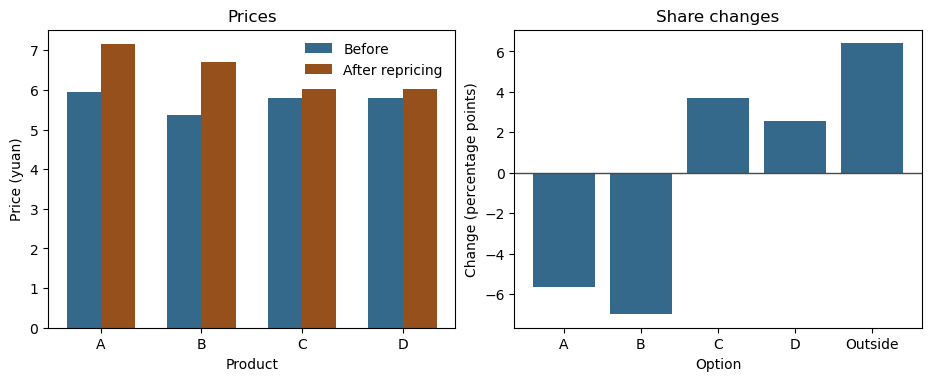

In [4]:
baseline_all = np.r_[baseline_shares, outside_shares[0]]
merger_all = np.r_[merger_shares, outside_shares[1]]
share_change_pp = 100 * (merger_all - baseline_all)
np.testing.assert_allclose(share_change_pp.sum(), 0, atol=1e-10)

figure, (price_axis, share_axis) = plt.subplots(1, 2, figsize=(9.2, 3.7), layout="constrained")
positions = np.arange(len(products))
price_axis.bar(positions - 0.17, baseline_price, width=0.34, color="#35698b", label="Before")
price_axis.bar(positions + 0.17, merger_price, width=0.34, color="#96501c", label="After repricing")
price_axis.set_xticks(positions, products)
price_axis.set(xlabel="Product", ylabel="Price (yuan)", title="Prices")
price_axis.legend(frameon=False, loc="upper right")
share_axis.bar((*products, "Outside"), share_change_pp, color="#35698b")
share_axis.axhline(0, color="#484848", linewidth=1)
share_axis.set(xlabel="Option", ylabel="Change (percentage points)", title="Share changes")
plt.show()

## 4. 对齐基准份额，再比较需求侧假设

第 8 课对每个试算的异质性参数反演一组平均效用。这里将异质性从 $\sigma=1.05$ 改为零，再反演出满足相同基准份额的平均效用。不改变价格斜率，然后在两种需求模型里只给 A 涨价 0.50 元，观察向 B 转移的份额占 A 流失份额的比例。

这一比较固定了基准报价、份额和价格系数。若进一步在两个模型下反演成本并重新求价格，两种模型通常会推得不同的隐含成本。报告时要说明哪些量改变了。

In [5]:
plain_delta, iterations, inverse_error = invert_shares(
    baseline_shares[None, :], characteristic[None, :], 0.0, nodes, weights
)
plain_nonprice_utility = plain_delta[0] + alpha * baseline_price
plain_shares, _ = demand(baseline_price, plain_nonprice_utility, 0.0)
np.testing.assert_allclose(plain_shares, baseline_shares, atol=1e-9, rtol=0)

higher_a = baseline_price.copy()
higher_a[0] += 0.5
for name, intercepts, dispersion in [
    ("随机系数需求", nonprice_utility, sigma),
    ("基准份额相同的普通 Logit", plain_nonprice_utility, 0.0),
]:
    higher_shares, _ = demand(higher_a, intercepts, dispersion)
    change = higher_shares - baseline_shares
    print(f"{name} · B 承接 A 流失份额的比例 {change[1] / -change[0]:.2%}")

随机系数需求 · B 承接 A 流失份额的比例 49.92%
基准份额相同的普通 Logit · B 承接 A 流失份额的比例 35.93%


## 练习

1. 用两个不同差分步长从价格扰动逆推出弹性矩阵。用公式解释为什么提高 A 的报价会改变外部选项的份额。本例的份额导数矩阵为什么是对称的？若各产品的价格系数不同，说明所有权方程如何使用导数矩阵的行与列。
2. 改为 A 和 C 归同一个所有者，保留 C 和 D 共享原有经营者的逻辑，即合并 A 与原来的 C、D 企业。再做一个只改变 A、B 所有权但合并后成本下降 10% 的情景。对两组情景报告价格固定时和企业重新定价后的价格、份额、消费者剩余及局部曲率。
3. 用第 4 节的普通 Logit 在观察价格下反演成本，再求 A、B 合并后的价格。比较其份额、弹性、隐含成本和兼并预测。解释为什么同一组基准份额无法充分固定反事实。
4. 选择第 8 课一个市场，用估计得到的异质性参数反演平均效用并校准初始点。写出你愿意施加的所有权和定价假设，计算对应的隐含成本。若出现负成本、不合意的价格或局部曲率检查失败，说明是哪个假设或数值环节需要检查。完整要求见[作业四及学期项目](../ASSIGNMENTS.md)。

本课核对了模拟价格候选解的局部条件。应用于真实市场时，分析还要论证所有权、定价行为与成本是否可信，并区分需求估计、供给假设和求解证据。 [Berry、Levinsohn 与 Pakes（1995）](https://pages.stern.nyu.edu/~wgreene/Econometrics/BLP.pdf)